# 04 Forecast wins vs portfolio wins

**Question: do better forecasts give better portfolios?** Checks whether the models that forecast
volatility best also build the best volatility-managed portfolios. It reads the portfolio results
saved by `01_build_portfolios.ipynb` and `02_eval_vs_buy_and_hold.ipynb` (run those first) and
computes forecast accuracy on the same out-of-sample months and models.

- **Forecast accuracy**, per model and ETF: mean QLIKE of the level forecast `fc_level` against
  realised variance (the headline loss, lower is better), plus MSE of the level and of the log
  forecast `fc_log` against log realised variance.
- **Portfolio performance**: the annualised Sharpe ratio of each per-ETF managed series and of the
  cyclical bucket, under the σ̄² specification set by `SPEC`.
- **Comparison**: for each ETF (and the cyclical bucket), the best forecast model, the best
  portfolio model, whether they agree, and the Spearman rank correlation across models between
  forecast accuracy and Sharpe ratio.

## Setup

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from portfolio_utils import (
    PORTFOLIO_DIR, EVAL_DIR, load_monthly_returns, load_forecast_files, forecast_wide, qlike,
)

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:.4f}".format)

# Which sigma2_bar specification's Sharpe ratios to compare with forecast accuracy:
# "fixed" (main) or "expanding" (extension). Forecast losses do not depend on it.
SPEC = "fixed"

# Optional reference model (a value of the `model` column, e.g. "garch"). None leaves the gain
# columns out.
BASELINE_MODEL = None

### Load the saved portfolio results

The models, tickers and out-of-sample window all come from `results/portfolios/run_info.json`, so
this notebook always matches the latest run of `01_build_portfolios.ipynb`. The Sharpe ratios come
from the tables saved by `02_eval_vs_buy_and_hold.ipynb`.

In [2]:
run_info = json.loads((PORTFOLIO_DIR / "run_info.json").read_text())
SELECTED = run_info["selected"]
VARIANTS = [v for variants in SELECTED.values() for v in variants]
TICKERS = run_info["tickers"]
oos_first, oos_last = (pd.Period(m, "M").to_timestamp("M") for m in run_info["oos_window"])
assert SPEC in run_info["specs"], f"{SPEC} is not among the saved specifications"

per_etf = pd.read_csv(EVAL_DIR / f"vs_bh_per_etf_{SPEC}.csv", index_col=["model", "ETF"])
bucket_summary = pd.read_csv(EVAL_DIR / f"vs_bh_bucket_{SPEC}.csv", index_col="portfolio")
assert set(per_etf.index.get_level_values("model")) == set(VARIANTS), \
    "evaluation tables do not match run_info: rerun 02_eval_vs_buy_and_hold.ipynb"

print("Models:", VARIANTS)
print("Specification:", SPEC)
print(f"Out-of-sample window: {oos_first:%Y-%m} to {oos_last:%Y-%m}")
print(f"Forecast column used for the portfolios: {run_info['forecast_col']}")
if BASELINE_MODEL is not None:
    assert BASELINE_MODEL in VARIANTS, f"{BASELINE_MODEL} is not among the saved models"

Models: ['garch', 'garch_midas_baa10y', 'ols_1m', 'en_full_macro', 'en_no_macro', 'en_no_vix', 'xgb_full_macro', 'xgb_no_macro', 'xgb_no_vix', 'xgb_vix_only']
Specification: fixed
Out-of-sample window: 2008-03 to 2025-12
Forecast column used for the portfolios: fc_level


## Forecast accuracy

Forecasts are re-indexed to their holding month t+1 (the row dated t is the forecast for t+1, as
in `01_build_portfolios.ipynb`) and restricted to the same out-of-sample months as the
portfolios. Realised variance comes from the price data for every model, so all models are scored
against the same target:

- QLIKE = RV / σ̂² − log(RV / σ̂²) − 1, with σ̂² = `fc_level`;
- MSE_level = (RV − σ̂²)²;
- MSE_log = (log RV − `fc_log`)².

In [3]:
_, rv_monthly = load_monthly_returns(TICKERS)
forecasts_raw = load_forecast_files(SELECTED)

oos_idx = rv_monthly.loc[oos_first:oos_last].index
rv = rv_monthly.loc[oos_idx, TICKERS]

loss_rows = {}
for family, variants in SELECTED.items():
    for v in variants:
        fc_level = forecast_wide(forecasts_raw[family], v, "fc_level", TICKERS).reindex(oos_idx)
        fc_log = forecast_wide(forecasts_raw[family], v, "fc_log", TICKERS).reindex(oos_idx)
        assert not fc_level.isna().any().any(), f"{v}: missing forecasts in the OOS window"
        loss_rows[v] = pd.DataFrame({
            "QLIKE": qlike(rv, fc_level).mean(),
            "MSE_level": ((rv - fc_level) ** 2).mean(),
            "MSE_log": ((np.log(rv) - fc_log) ** 2).mean(),
        })

forecast_loss = pd.concat(loss_rows, names=["model", "ETF"])
forecast_loss

QLIKE  MSE_level  MSE_log
model              ETF                           
garch              XLB 0.2411     0.0001   0.4343
                   XLE 0.2547     0.0002   0.4219
                   XLF 0.3054     0.0001   0.5748
                   XLI 0.2603     0.0001   0.4566
                   XLY 0.2538     0.0000   0.4749
garch_midas_baa10y XLB 0.2431     0.0001   0.4419
                   XLE 0.2587     0.0004   0.4323
                   XLF 0.3090     0.0002   0.5821
                   XLI 0.2632     0.0001   0.4649
                   XLY 0.2561     0.0000   0.4787
ols_1m             XLB 0.2958     0.0001   0.4616
                   XLE 0.2958     0.0002   0.4515
                   XLF 0.4036     0.0002   0.6640
                   XLI 0.3383     0.0001   0.5282
                   XLY 0.2969     0.0000   0.5042
en_full_macro      XLB 0.2792     0.0003   0.4199
                   XLE 0.3568     0.0002   0.4685
                   XLF 0.3923     0.0021   0.6124
                   XLI 0.2997     0.0007   0.4546
                   XLY 0.2927     0.0020   0.4910
en_no_macro        XLB 0.2958     0.0001   0.4615
                   XLE 0.2958     0.0002   0.4514
                   XLF 0.4035     0.0002   0.6637
                   XLI 0.3383     0.0001   0.5281
                   XLY 0.2969     0.0000   0.5041
en_no_vix          XLB 0.3298     0.0002   0.4786
                   XLE 0.3692     0.0002   0.4807
                   XLF 0.4603     0.0015   0.6688
                   XLI 0.3944     0.0001   0.5277
                   XLY 0.3421     0.0002   0.5250
xgb_full_macro     XLB 0.3582     0.0001   0.4595
                   XLE 0.4145     0.0003   0.4991
                   XLF 0.4795     0.0002   0.6388
                   XLI 0.3929     0.0001   0.4768
                   XLY 0.3353     0.0000   0.5012
xgb_no_macro       XLB 0.3565     0.0001   0.5268
                   XLE 0.3606     0.0002   0.4892
                   XLF 0.4485     0.0002   0.7100
                   XLI 0.3762     0.0001   0.5595
                   XLY 0.3949     0.0000   0.6181
xgb_no_vix         XLB 0.3756     0.0001   0.5111
                   XLE 0.4226     0.0003   0.5016
                   XLF 0.5414     0.0002   0.6943
                   XLI 0.4078     0.0001   0.5338
                   XLY 0.3805     0.0000   0.5429
xgb_vix_only       XLB 0.3120     0.0001   0.4514
                   XLE 0.3859     0.0002   0.5002
                   XLF 0.4671     0.0003   0.6785
                   XLI 0.3315     0.0001   0.4637
                   XLY 0.3165     0.0000   0.5262

## Forecast ranks vs portfolio ranks

Rank 1 is best: lowest mean QLIKE for the forecast, highest Sharpe ratio for the portfolio. The
cyclical row ranks models by their QLIKE averaged over the cyclical ETFs and by the Sharpe ratio
of the managed cyclical bucket.

In [4]:
qlike_tbl = forecast_loss["QLIKE"].unstack("ETF")[TICKERS].loc[VARIANTS]   # rows: model
sharpe_tbl = per_etf["SR_managed"].unstack("ETF")[TICKERS].loc[VARIANTS]

qlike_tbl["Cyclical"] = qlike_tbl[TICKERS].mean(axis=1)
sharpe_tbl["Cyclical"] = bucket_summary.loc[VARIANTS, "ann_sharpe"]

ranks = pd.concat({"QLIKE_rank": qlike_tbl.rank(), "SR_rank": sharpe_tbl.rank(ascending=False)},
                  axis=1).astype(int)
pd.concat({"QLIKE": qlike_tbl, "SR_managed": sharpe_tbl}, axis=1)

QLIKE                                      SR_managed                                     
ETF                   XLB    XLE    XLF    XLI    XLY Cyclical        XLB    XLE    XLF    XLI    XLY Cyclical
model                                                                                                         
garch              0.2411 0.2547 0.3054 0.2603 0.2538   0.2631     0.2328 0.1202 0.5956 0.6061 0.8068   0.4966
garch_midas_baa10y 0.2431 0.2587 0.3090 0.2632 0.2561   0.2660     0.2318 0.1153 0.5961 0.5983 0.8066   0.4938
ols_1m             0.2958 0.2958 0.4036 0.3383 0.2969   0.3261     0.1987 0.1006 0.5155 0.5343 0.7917   0.4535
en_full_macro      0.2792 0.3568 0.3923 0.2997 0.2927   0.3242     0.1277 0.0813 0.4689 0.4608 0.7270   0.3990
en_no_macro        0.2958 0.2958 0.4035 0.3383 0.2969   0.3261     0.1989 0.1006 0.5156 0.5343 0.7918   0.4536
en_no_vix          0.3298 0.3692 0.4603 0.3944 0.3421   0.3791     0.1739 0.0875 0.4846 0.4560 0.7223   0.4161
xgb_full_macro     0.3582 0.4145 0.4795 0.3929 0.3353   0.3961     0.1010 0.0042 0.4610 0.4221 0.6663   0.3375
xgb_no_macro       0.3565 0.3606 0.4485 0.3762 0.3949   0.3874     0.1898 0.0503 0.4678 0.5194 0.8176   0.4284
xgb_no_vix         0.3756 0.4226 0.5414 0.4078 0.3805   0.4256     0.2116 0.0032 0.4600 0.5053 0.7637   0.3982
xgb_vix_only       0.3120 0.3859 0.4671 0.3315 0.3165   0.3626     0.1687 0.0511 0.5097 0.4938 0.6896   0.4040

In [5]:
ranks.swaplevel(axis=1).sort_index(axis=1, level=0, sort_remaining=False)

ETF                  Cyclical                XLB                XLE                XLF                XLI                XLY        
                   QLIKE_rank SR_rank QLIKE_rank SR_rank QLIKE_rank SR_rank QLIKE_rank SR_rank QLIKE_rank SR_rank QLIKE_rank SR_rank
model                                                                                                                               
garch                       1       1          1       1          1       1          1       2          1       1          1       2
garch_midas_baa10y          2       2          2       2          2       2          2       1          2       2          2       3
ols_1m                      4       4          4       5          3       4          5       4          5       3          5       5
en_full_macro               3       8          3       9          5       6          3       7          3       8          3       7
en_no_macro                 5       3          5       4          4       3          4       3          6       4          4       4
en_no_vix                   7       6          7       7          7       5          7       6          9       9          8       8
xgb_full_macro              9      10          9      10          9       9          9       9          8      10          7      10
xgb_no_macro                8       5          8       6          6       8          6       8          7       5         10       1
xgb_no_vix                 10       9         10       3         10      10         10      10         10       6          9       6
xgb_vix_only                6       7          6       8          8       7          8       5          4       7          6       9

## Summary: do forecast wins carry through?

Per ETF and for the cyclical bucket:

- **best_forecast_model** (lowest QLIKE) and **best_portfolio_model** (highest Sharpe), and
  whether they are the same model;
- **spearman_rho**: rank correlation across models between forecast accuracy (−QLIKE) and Sharpe
  ratio. Positive means better forecasts tend to give better portfolios; with only a handful of
  models it is descriptive, not a test.
- If `BASELINE_MODEL` is set: **QLIKE_gain_vs_base** = 1 − QLIKE_best / QLIKE_base (share of the
  baseline's loss removed) and **SR_gain_vs_base** = SR_best − SR_base.

In [6]:
summary = pd.DataFrame({
    "best_forecast_model": qlike_tbl.idxmin(),
    "best_portfolio_model": sharpe_tbl.idxmax(),
    "spearman_rho": pd.Series({col: (-qlike_tbl[col]).corr(sharpe_tbl[col], method="spearman")
                               for col in qlike_tbl.columns}),
})
summary.insert(2, "same_model", summary["best_forecast_model"] == summary["best_portfolio_model"])
summary["SR_of_best_forecast_model"] = [sharpe_tbl.at[m, col]
                                        for col, m in summary["best_forecast_model"].items()]
summary["SR_of_best_portfolio_model"] = sharpe_tbl.max()

if BASELINE_MODEL is not None:
    summary["QLIKE_gain_vs_base"] = 1 - qlike_tbl.min() / qlike_tbl.loc[BASELINE_MODEL]
    summary["SR_gain_vs_base"] = sharpe_tbl.max() - sharpe_tbl.loc[BASELINE_MODEL]

summary.rename_axis("ETF")

,best_forecast_model,best_portfolio_model,same_model,spearman_rho,SR_of_best_forecast_model,SR_of_best_portfolio_model
ETF,,,,,,
XLB,garch,garch,True,0.4182,0.2328,0.2328
XLE,garch,garch,True,0.9273,0.1202,0.1202
XLF,garch,garch_midas_baa10y,False,0.7939,0.5956,0.5961
XLI,garch,garch,True,0.6000,0.6061,0.6061
XLY,garch,xgb_no_macro,False,0.2364,0.8068,0.8176
Cyclical,garch,garch,True,0.7455,0.4966,0.4966


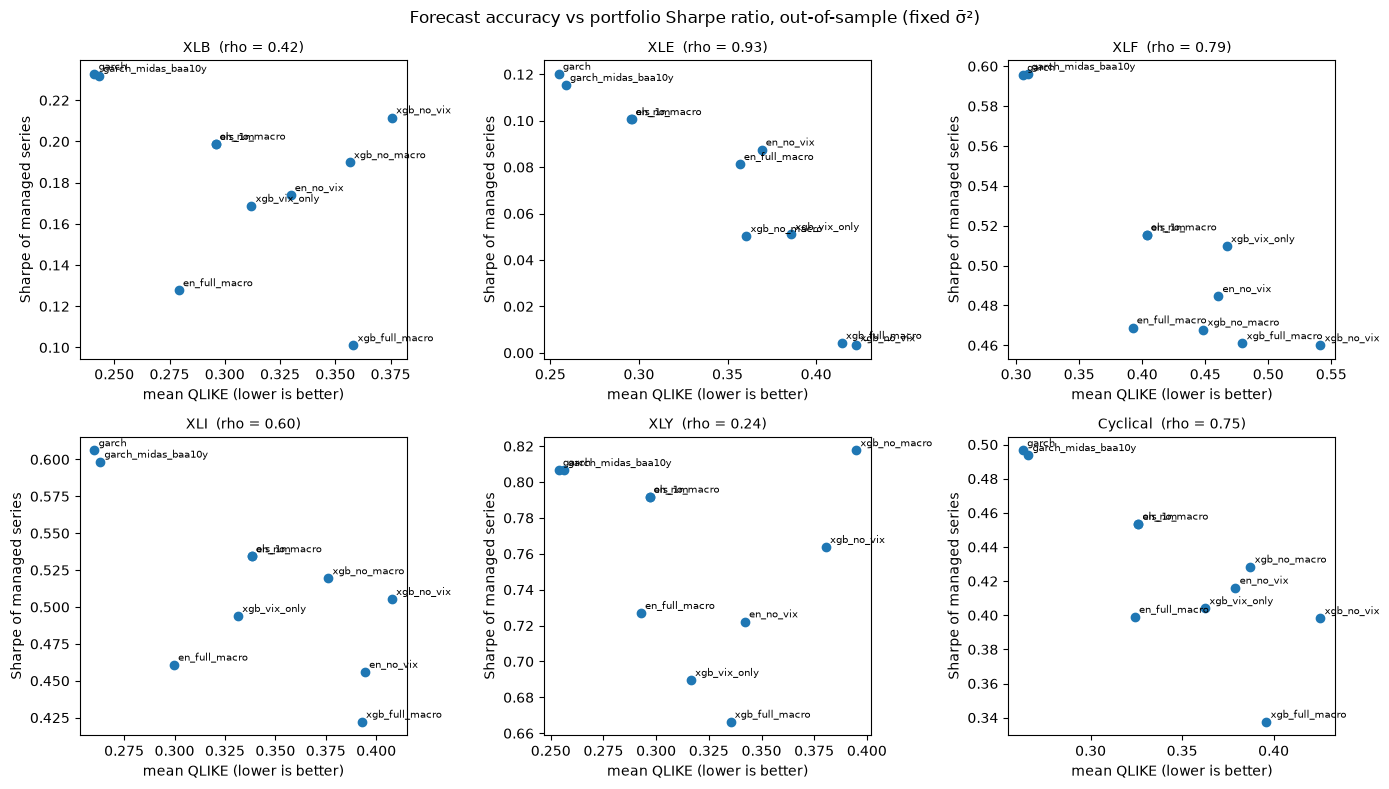

In [7]:
cols = list(qlike_tbl.columns)
fig, axes = plt.subplots(2, 3, figsize=(14, 8), squeeze=False)
for ax, col in zip(axes.flat, cols):
    ax.scatter(qlike_tbl[col], sharpe_tbl[col])
    for m in VARIANTS:
        ax.annotate(m, (qlike_tbl.at[m, col], sharpe_tbl.at[m, col]), fontsize=7,
                    xytext=(3, 3), textcoords="offset points")
    ax.set_title(f"{col}  (rho = {summary.at[col, 'spearman_rho']:.2f})", fontsize=10)
    ax.set_xlabel("mean QLIKE (lower is better)")
    ax.set_ylabel("Sharpe of managed series")
for ax in axes.flat[len(cols):]:
    ax.set_visible(False)
fig.suptitle(f"Forecast accuracy vs portfolio Sharpe ratio, out-of-sample ({SPEC} σ̄²)")
fig.tight_layout()
plt.show()

## Save the tables

Written to `results/eval/`:

- `forecast_losses.csv`: QLIKE, MSE_level and MSE_log per model and ETF;
- `forecast_vs_portfolio_<SPEC>.csv`: the summary above, for the specification in `SPEC`.

In [8]:
EVAL_DIR.mkdir(parents=True, exist_ok=True)
forecast_loss.to_csv(EVAL_DIR / "forecast_losses.csv")
summary.rename_axis("ETF").to_csv(EVAL_DIR / f"forecast_vs_portfolio_{SPEC}.csv")
print("Saved to", EVAL_DIR.resolve())

Saved to C:\Documents\NUS\Y4S1\DSE4101\dse4101capstone_project\scripts\portfolio_construction\results\eval
